In [1]:
!pip install -q transformers accelerate

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from transformers import (
    SegformerImageProcessor,
    SegformerForSemanticSegmentation
)

print("Libraries imported successfully!")
print("GPU Available:", torch.cuda.is_available())

Libraries imported successfully!
GPU Available: True


Image downloaded successfully!
Image dimensions: (7839, 4899)


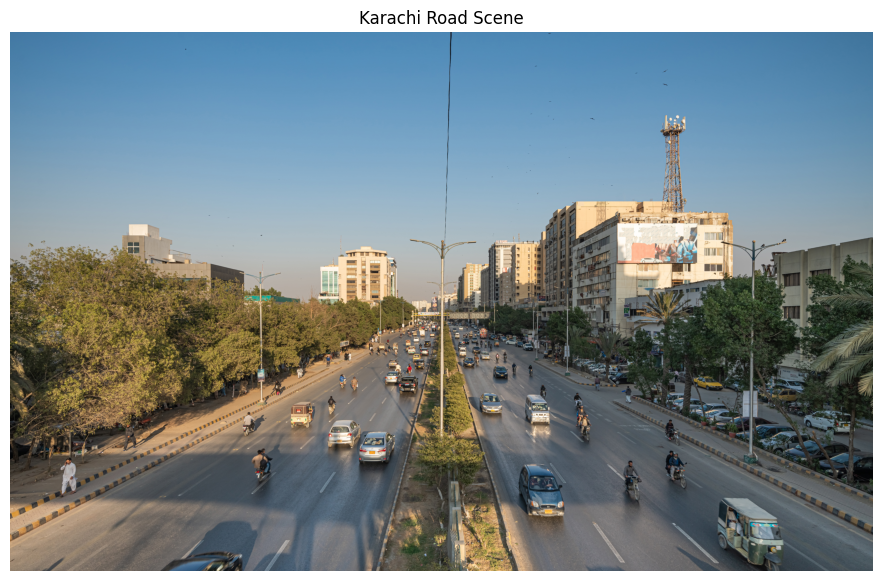

In [4]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

filename = "PK_Karachi_asv2020-02_img90_Highway_at_PECHS.jpg"

# Request image information from Wikimedia API
api_url = "https://commons.wikimedia.org/w/api.php"

headers = {
    "User-Agent": "KarachiRoadSegmentation/1.0 (educational project)"
}

params = {
    "action": "query",
    "titles": f"File:{filename}",
    "prop": "imageinfo",
    "iiprop": "url",
    "format": "json"
}

response = requests.get(
    api_url,
    params=params,
    headers=headers,
    timeout=60
)

response.raise_for_status()

data = response.json()
pages = data["query"]["pages"]
image_url = next(iter(pages.values()))["imageinfo"][0]["url"]

# Download image
response = requests.get(
    image_url,
    headers=headers,
    timeout=60
)

response.raise_for_status()

image = Image.open(BytesIO(response.content)).convert("RGB")
image.save("/kaggle/working/karachi_road.jpg")

print("Image downloaded successfully!")
print("Image dimensions:", image.size)

plt.figure(figsize=(12, 7))
plt.imshow(image)
plt.title("Karachi Road Scene")
plt.axis("off")
plt.show()

In [5]:
MODEL_NAME = "nvidia/segformer-b0-finetuned-cityscapes-1024-1024"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

processor = SegformerImageProcessor.from_pretrained(MODEL_NAME)

model = SegformerForSemanticSegmentation.from_pretrained(
    MODEL_NAME
).to(device)

model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Model:", MODEL_NAME)

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 15.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Model loaded successfully!
Device: cuda
Model: nvidia/segformer-b0-finetuned-cityscapes-1024-1024


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.9MB            

model.safetensors: downloading bytes:           |  0.00B            

In [6]:
# Prepare image for the model
inputs = processor(images=image, return_tensors="pt")

# Move inputs to GPU
inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# Perform prediction
with torch.no_grad():
    outputs = model(**inputs)

# Resize predictions to original image dimensions
logits = torch.nn.functional.interpolate(
    outputs.logits,
    size=(image.height, image.width),
    mode="bilinear",
    align_corners=False
)

# Get predicted class for every pixel
segmentation_map = logits.argmax(dim=1)[0].cpu().numpy()

print("Segmentation completed successfully!")
print("Segmentation map shape:", segmentation_map.shape)
print("Detected class IDs:", np.unique(segmentation_map))

Segmentation completed successfully!
Segmentation map shape: (4899, 7839)
Detected class IDs: [ 0  1  2  3  4  5  7  8  9 10 11 13 17 18]


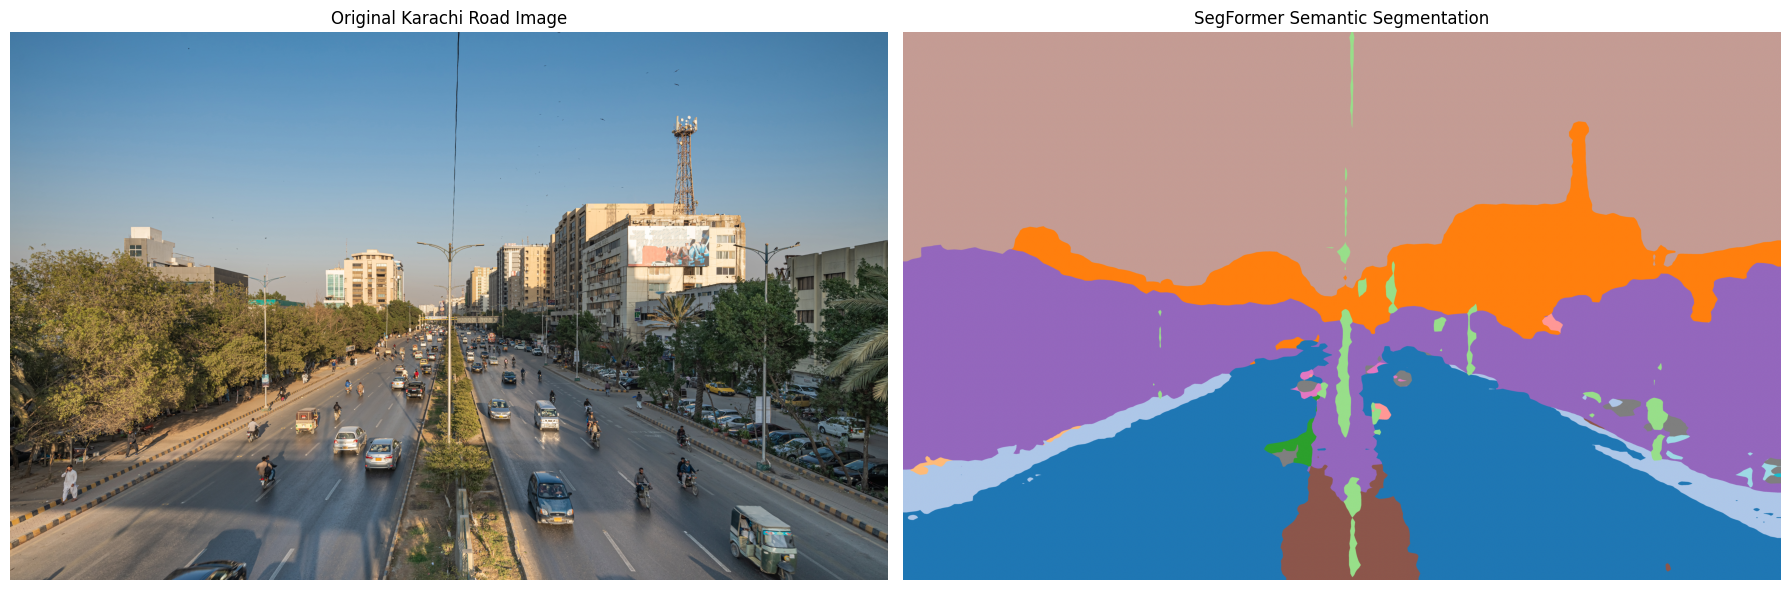

In [7]:
plt.figure(figsize=(18, 8))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Karachi Road Image")
plt.axis("off")

# Segmentation map
plt.subplot(1, 2, 2)
plt.imshow(segmentation_map, cmap="tab20")
plt.title("SegFormer Semantic Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

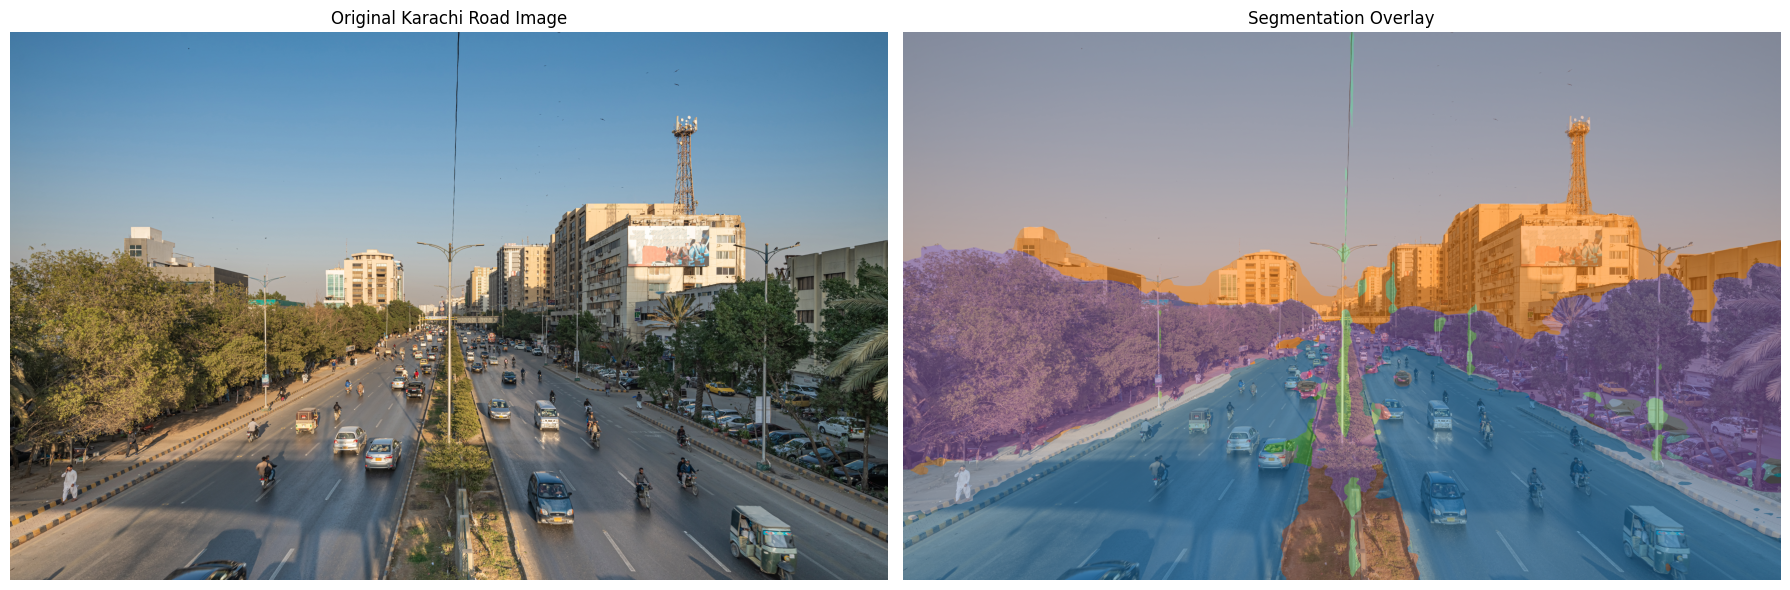

Detected Objects:
Class 0: road
Class 1: sidewalk
Class 2: building
Class 3: wall
Class 4: fence
Class 5: pole
Class 7: traffic sign
Class 8: vegetation
Class 9: terrain
Class 10: sky
Class 11: person
Class 13: car
Class 17: motorcycle
Class 18: bicycle

Overlay saved successfully!


In [8]:
import matplotlib.patches as mpatches

# Get class names
id2label = model.config.id2label
detected_ids = np.unique(segmentation_map)

# Create color map
cmap = plt.get_cmap("tab20", len(id2label))

# Convert segmentation map into RGB colors
colored_mask = (cmap(segmentation_map)[..., :3] * 255).astype(np.uint8)

# Create overlay
original_array = np.array(image)
overlay = (
    0.5 * original_array + 0.5 * colored_mask
).astype(np.uint8)

# Display original and overlay
plt.figure(figsize=(18, 9))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Karachi Road Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(overlay)
plt.title("Segmentation Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

# Display detected classes
print("Detected Objects:")

for class_id in detected_ids:
    print(f"Class {class_id}: {id2label[int(class_id)]}")

# Save result
Image.fromarray(overlay).save(
    "/kaggle/working/karachi_segmentation_overlay.png"
)

print("\nOverlay saved successfully!")

In [9]:
# Count pixels belonging to each predicted class
class_ids, pixel_counts = np.unique(
    segmentation_map,
    return_counts=True
)

total_pixels = segmentation_map.size

print("SEGMENTATION ANALYSIS")
print("-" * 45)

for class_id, count in zip(class_ids, pixel_counts):

    class_name = id2label[int(class_id)]
    percentage = (count / total_pixels) * 100

    print(
        f"{class_name}: "
        f"{percentage:.2f}% of image"
    )

# Save raw segmentation map
np.save(
    "/kaggle/working/karachi_segmentation_map.npy",
    segmentation_map
)

print("\nSegmentation map saved successfully!")

SEGMENTATION ANALYSIS
---------------------------------------------
road: 23.51% of image
sidewalk: 2.77% of image
building: 8.37% of image
wall: 0.08% of image
fence: 0.19% of image
pole: 0.97% of image
traffic sign: 0.08% of image
vegetation: 22.36% of image
terrain: 2.18% of image
sky: 38.96% of image
person: 0.07% of image
car: 0.36% of image
motorcycle: 0.00% of image
bicycle: 0.10% of image

Segmentation map saved successfully!
